check to a one cavity file

In [25]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset
from sklearn.manifold import TSNE


# ========================================
# 1. データの読み込み
# ========================================

data = torch.load(
    "/workspace/lustre/work/pdl18409/shared/data/anomaly-detection/teams/the-outliers/filtered_data_tensor-MBL-090RFC__RFS-EVR-101.pt",
    map_location="cpu",
    weights_only=True
)

data = data.float()

print("Original data:", data.shape)

# ========================================
# 2. Train / Validation / Test に分割
# ========================================

n = len(data)

n_train = int(n * 0.8)
n_val = int(n * 0.1)

# ランダムにせず、順番通りに分割
train_data = data[:n_train]
val_data = data[n_train:n_train+n_val]
test_data = data[n_train+n_val:]

print("Train:", train_data.shape)
print("Validation:", val_data.shape)
print("Test:", test_data.shape)

# ========================================
# 3. 標準化
# ========================================

# Trainデータからチャンネルごとの平均と標準偏差を計算
mean_train = train_data.mean(dim=-1, keepdim=True)
std_train = train_data.std(dim=-1, keepdim=True)
mean_val = val_data.mean(dim=-1, keepdim=True)
std_val = val_data.std(dim=-1, keepdim=True)
mean_test = test_data.mean(dim=-1, keepdim=True)
std_test = test_data.std(dim=-1, keepdim=True)

# 同じ平均・標準偏差で標準化
train_data = (train_data - mean_train) / std_train
val_data = (val_data - mean_val) / std_val
test_data = (test_data - mean_test) / std_test

# ========================================
# 4. DataLoaderの作成
# ========================================

batch_size = 4

train_loader = DataLoader(
    TensorDataset(train_data),
    batch_size=batch_size,
    shuffle=False
)

val_loader = DataLoader(
    TensorDataset(val_data),
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    TensorDataset(test_data),
    batch_size=batch_size,
    shuffle=False
)

Original data: torch.Size([311, 6, 35221])
Train: torch.Size([248, 6, 35221])
Validation: torch.Size([31, 6, 35221])
Test: torch.Size([32, 6, 35221])


Device: cuda
Epoch 1/20 Train Loss: 0.985030 Val Loss: 0.817276
Epoch 2/20 Train Loss: 0.504688 Val Loss: 0.319897
Epoch 3/20 Train Loss: 0.267113 Val Loss: 0.170979
Epoch 4/20 Train Loss: 0.151310 Val Loss: 0.123988
Epoch 5/20 Train Loss: 0.123384 Val Loss: 0.107725
Epoch 6/20 Train Loss: 0.101493 Val Loss: 0.079752
Epoch 7/20 Train Loss: 0.069852 Val Loss: 0.056460
Epoch 8/20 Train Loss: 0.055200 Val Loss: 0.051283
Epoch 9/20 Train Loss: 0.051093 Val Loss: 0.051275
Epoch 10/20 Train Loss: 0.051385 Val Loss: 0.043360
Epoch 11/20 Train Loss: 0.051698 Val Loss: 0.043308
Epoch 12/20 Train Loss: 0.048898 Val Loss: 0.041000
Epoch 13/20 Train Loss: 0.047041 Val Loss: 0.040962
Epoch 14/20 Train Loss: 0.046756 Val Loss: 0.043298
Epoch 15/20 Train Loss: 0.046496 Val Loss: 0.048109
Epoch 16/20 Train Loss: 0.045911 Val Loss: 0.042931
Epoch 17/20 Train Loss: 0.044021 Val Loss: 0.035962
Epoch 18/20 Train Loss: 0.041565 Val Loss: 0.035043
Epoch 19/20 Train Loss: 0.039979 Val Loss: 0.034677
Epoch 20

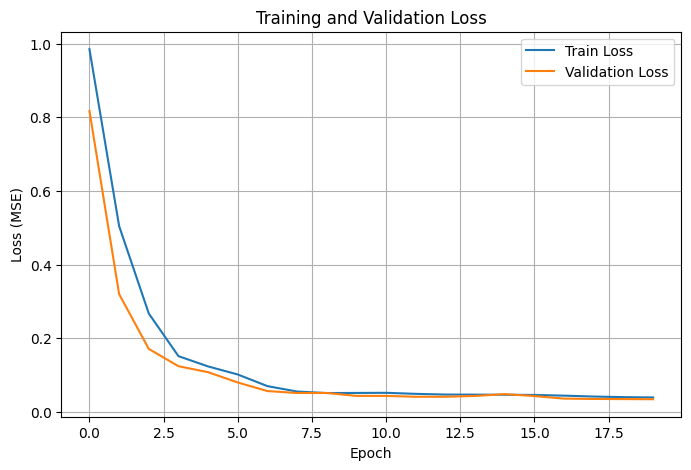

Train mean error: 0.03859437
Validation mean error: 0.034316864
Test mean error: 0.03301187


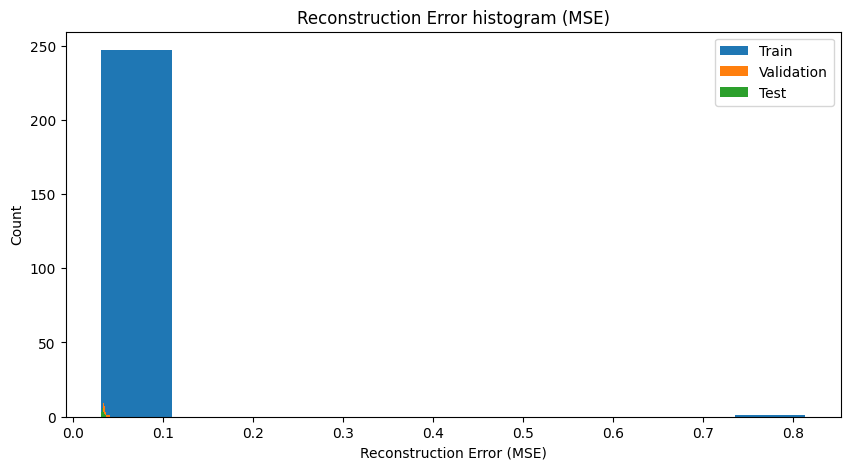

In [12]:
# ========================================
# 5. Autoencoderモデル
# ========================================

class RFAutoencoder(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Conv1d(6, 12, kernel_size=8, stride=4, padding=2),
            nn.GELU(),

            nn.Conv1d(12, 24, kernel_size=8, stride=4, padding=2),
            nn.GELU(),

            nn.Flatten(),
            nn.Linear(52824, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 52824),
            nn.Unflatten(1, (24, 2201)),

            nn.ConvTranspose1d(
                24, 12,
                kernel_size=8,
                stride=4,
                padding=2,
                output_padding=1
            ),
            nn.GELU(),

            nn.ConvTranspose1d(
                12, 6,
                kernel_size=8,
                stride=4,
                padding=2,
                output_padding=1
            )
        )

    def forward(self, x):
        z = self.encoder(x)
        reconstructed = self.decoder(z)
        return reconstructed


# ========================================
# 6. モデルとLoss関数の設定
# ========================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = RFAutoencoder(latent_dim=2).to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print("Device:", device)

# ========================================
# 7. 学習
# ========================================

epochs = 20

train_losses = []
val_losses = []

for epoch in range(epochs):

    # ----- Train -----
    model.train()
    train_loss = 0

    for (x,) in train_loader:
        x = x.to(device)

        optimizer.zero_grad()

        output = model(x)
        loss = criterion(output, x)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * x.size(0)

    train_loss /= len(train_data)
    train_losses.append(train_loss)

    # ----- Validation -----
    model.eval()
    val_loss = 0

    with torch.no_grad():
        for (x,) in val_loader:
            x = x.to(device)

            output = model(x)
            loss = criterion(output, x)

            val_loss += loss.item() * x.size(0)

    val_loss /= len(val_data)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch+1}/{epochs} "
        f"Train Loss: {train_loss:.6f} "
        f"Val Loss: {val_loss:.6f}"
    )

torch.save(model, "model-MBL-090RFC_RFS-EVR-101.pt")
# ========================================
# 8. Lossのグラフ
# ========================================

plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.savefig("loss_function-MBL-090RFC_RFS-EVR-101.pdf",dpi=300)
plt.show()

# ========================================
# 9. 再構成誤差の計算
# ========================================

def calculate_errors(loader):
    model.eval()
    errors = []

    with torch.no_grad():
        for (x,) in loader:
            x = x.to(device)

            reconstructed = model(x)

            # 各イベントの再構成誤差（MSE）
            error = ((x - reconstructed) ** 2).mean(dim=(1, 2))

            errors.extend(error.cpu().numpy())

    return np.array(errors)


train_errors = calculate_errors(train_loader)
val_errors = calculate_errors(val_loader)
test_errors = calculate_errors(test_loader)

print("Train mean error:", train_errors.mean())
print("Validation mean error:", val_errors.mean())
print("Test mean error:", test_errors.mean())

# ========================================
# 10. 再構成誤差のグラフ
# ========================================

plt.figure(figsize=(10, 5))

plt.hist(
    train_errors,
    label="Train"
)

plt.hist(
    val_errors,
    label="Validation"
)

plt.hist(
    test_errors,
    label="Test"
)

plt.xlabel("Reconstruction Error (MSE)")
plt.ylabel("Count")
plt.title("Reconstruction Error histogram (MSE)")
plt.legend()
plt.savefig("reconstruction_error_histogram-MBL-090RFC_RFS-EVR-101.pdf", dpi=300)
plt.show()

In [26]:
model = torch.load("/workspace/lustre/work/pdl18409/shared/The_outliers/notebooks/model-MBL-090RFC_RFS-EVR-101.pt",weights_only=False)

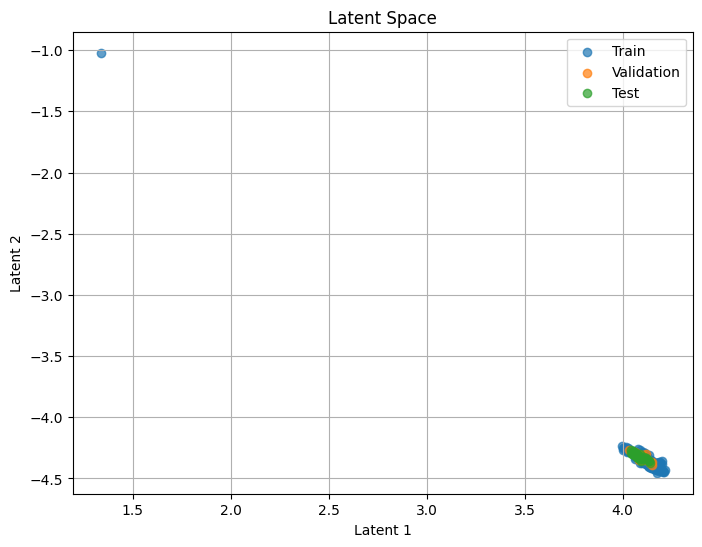

In [15]:
# ========================================
# 11. Latent Spaceの可視化
# ========================================
from sklearn.manifold import TSNE

'''
def get_latent(loader):
    model.eval()
    latent_list = []

    with torch.no_grad():
        for batch in loader:
            if isinstance(batch, (list, tuple)):
                x = batch[0]
            else:
                x = batch
                
            x = x.to(device)

            # Encoderで2次元に圧縮
            z = model.encoder(x)
            if z.ndim > 2:
                z = z.flatten(start_dim = 1)

            latent_list.append(z.cpu())

    latent_tensor = torch.cat(latent_list, dim=0)
    latent_np = latent_tensor.numpy()
    tsne = TSNE(n_components=2, perplexity=30, random_state=42)
    latent = tsne.fit_transform(latent_np)
    return latent
'''

def get_latent(loader):
    model.eval()
    latent_list = []

    with torch.no_grad():
        for batch in loader:
            if isinstance(batch, (list, tuple)):
                x = batch[0]
            else:
                x = batch
                
            x = x.to(device)

            # Encoderで2次元に圧縮
            z = model.encoder(x)
            if z.ndim > 2:
                z = z.flatten(start_dim = 1)

            latent_list.append(z.cpu())

    latent_tensor = torch.cat(latent_list, dim=0)
    return latent_tensor


# 各データのLatent Spaceを取得
train_latent = get_latent(train_loader)
val_latent = get_latent(val_loader)
test_latent = get_latent(test_loader)


# グラフ表示
plt.figure(figsize=(8, 6))

plt.scatter(
    train_latent[:, 0],
    train_latent[:, 1],
    label="Train",
    alpha=0.7
)

plt.scatter(
    val_latent[:, 0],
    val_latent[:, 1],
    label="Validation",
    alpha=0.7
)

plt.scatter(
    test_latent[:, 0],
    test_latent[:, 1],
    label="Test",
    alpha=0.7
)

plt.xlabel("Latent 1")
plt.ylabel("Latent 2")
plt.title("Latent Space")
plt.legend()
plt.grid(True)
plt.show()

In [27]:
# 異常データを読み込む
anomaly_data = torch.load(
    "/workspace/lustre/work/pdl18409/shared/data/anomaly-detection/teams/the-outliers/PM/step3_PM_tensors/MBL_PM_tensors/tensor_MBL-090RFC_RFS-DIG-101.pt",
    map_location="cpu",
    weights_only=True
)

# データの型
print(type(anomaly_data))

# 辞書のキーとデータ形状を表示
for key, value in anomaly_data.items():
    print(key, type(value), getattr(value, "shape", None))

<class 'dict'>
data <class 'torch.Tensor'> torch.Size([1311, 6, 35221])
cycle_id <class 'list'> None


In [28]:
print(anomaly_data.keys())

dict_keys(['data', 'cycle_id'])


In [29]:
print("Data:", anomaly_data["data"].shape)
print("Cycle ID count:", len(anomaly_data["cycle_id"]))

Data: torch.Size([1311, 6, 35221])
Cycle ID count: 1311


In [30]:
import numpy as np
import matplotlib.pyplot as plt

anomaly_wave = anomaly_data["data"].float()
anomaly_cycle_id = anomaly_data["cycle_id"]



model.eval()

latents = []
errors = []

with torch.no_grad():
    for i in range(0, len(anomaly_wave), 4):

        x = anomaly_wave[i:i+4]
        mean_anomaly = x.mean(dim=-1, keepdim=True)
        std_anomaly = x.std(dim=-1, keepdim=True)
        # 正常Trainデータの平均と標準偏差で標準化
        x = (x - mean_anomaly) / std_anomaly
        x = x.to(device)

        # EncoderとDecoder
        z = model.encoder(x)
        reconstructed = model.decoder(z)

        # 再構成誤差
        error = ((x - reconstructed)**2).mean(dim=(1, 2))

        latents.append(z.cpu())
        errors.append(error.cpu())

anomaly_latent = torch.cat(latents).numpy()
anomaly_errors = torch.cat(errors).numpy()

print("Latent:", anomaly_latent.shape)
print("Errors:", anomaly_errors.shape)

Latent: (1311, 2)
Errors: (1311,)


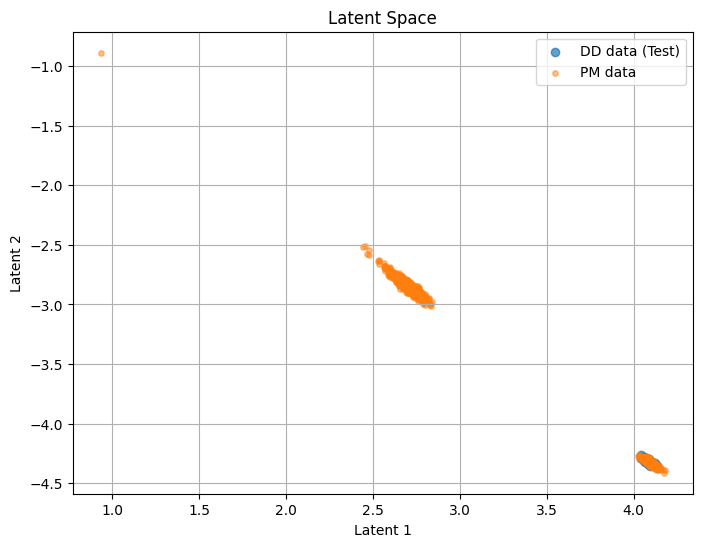

In [24]:
plt.figure(figsize=(8, 6))

plt.scatter(
    test_latent[:, 0],
    test_latent[:, 1],
    label="DD data (Test)",
    alpha=0.7
)

plt.scatter(
    anomaly_latent[:, 0],
    anomaly_latent[:, 1],
    label="PM data",
    alpha=0.5,
    s=15
)

plt.xlabel("Latent 1")
plt.ylabel("Latent 2")
plt.title("Latent Space")
plt.legend()
plt.grid(True)
plt.savefig("latent_space_DDandPM-MBL-090RFC__RFS-EVR-101.pdf", dpi=300)
plt.show()

In [71]:
import torch

threshold = 0.15
model.eval()

errors = []
latents = []  

with torch.no_grad():
  for i in range(0, len(anomaly_wave), 4):
    x = anomaly_wave[i : i + 4]
    mean_anomaly = x.mean(dim=-1, keepdim=True)
    std_anomaly = x.std(dim=-1, keepdim=True)
    x = (x - mean_anomaly) / (std_anomaly + 1e-8)
    x = x.to(device)

    # Encoder and Decoder
    z = model.encoder(x)
    reconstructed = model.decoder(z)

    # Reconstruction error
    error = ((x - reconstructed) ** 2).mean(dim=(1, 2))

    latents.append(z.cpu())
    errors.append(error.cpu())

errors = torch.cat(errors, dim=0)
latents = torch.cat(latents, dim=0)

pm_labels = torch.tensor([1] * len(anomaly_wave))

predictions = errors > threshold

# True positives (TP) and false positives (FP)
TP = ((predictions == 1) & (pm_labels == 1)).sum().item()
FN = ((predictions == 0) & (pm_labels == 1)).sum().item()

print(f"True Positives (TP) : {TP}")
print(f"False Negatives (FN) : {FN}")

model.eval()

test_errors = []
test_latents = []  

with torch.no_grad():
  for batch in test_loader:
    x = batch[0] if isinstance(batch, (list, tuple)) else batch
    
    mean_test = x.mean(dim=-1, keepdim=True)
    std_test = x.std(dim=-1, keepdim=True)
    x = (x - mean_test) / (std_test + 1e-8)
    x = x.to(device)

    z = model.encoder(x)
    reconstructed = model.decoder(z)

    error = ((x - reconstructed) ** 2).mean(dim=(1, 2))

    test_latents.append(z.cpu())
    test_errors.append(error.cpu())

test_errors = torch.cat(test_errors, dim=0)
test_latents = torch.cat(test_latents, dim=0)

dd_test_labels = torch.zeros(len(test_loader.dataset), dtype=torch.long)

predictions_test = test_errors > threshold

FP = ((predictions_test == 1) & (dd_test_labels == 0)).sum().item()
TN = ((predictions_test == 0) & (dd_test_labels == 0)).sum().item()

print(f"False Positives (FP) : {FP}")
print(f"True Negatives (TN) : {TN}")

Nombre total d'échantillons : 1311
True Positives (TP) : 1050
False Negatives (FN) : 261
Nombre total d'échantillons de test : 32
False Positives (FP - fausses alarmes) : 0
True Negatives (TN - bons normaux) : 32


              precision    recall  f1-score   support

  Normal (0)       0.11      1.00      0.20        32
 Anomaly (1)       1.00      0.80      0.89      1311

    accuracy                           0.81      1343
   macro avg       0.55      0.90      0.54      1343
weighted avg       0.98      0.81      0.87      1343

=== Some metrics (threshold = 0.15) ===
Accuracy    : 0.8057
Precision   : 1.0000
Recall (TP) : 0.8009
Specificity : 1.0000
F1-score    : 0.8895
---------------------------------------------


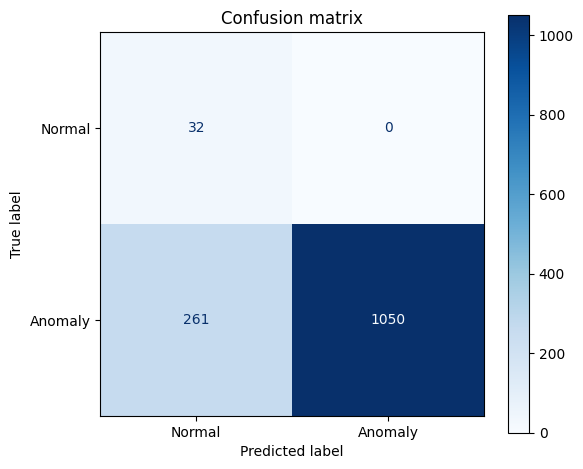

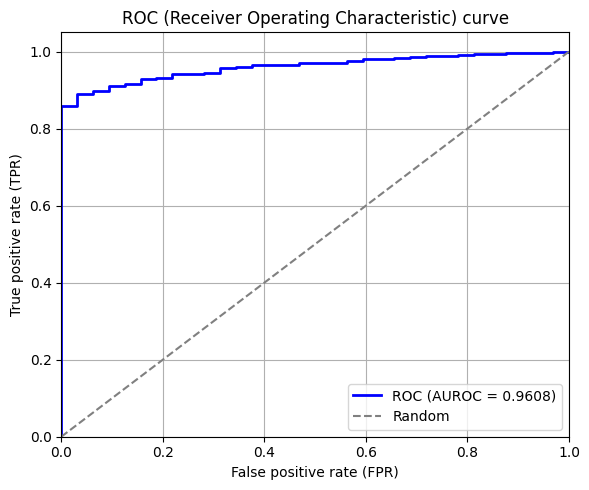

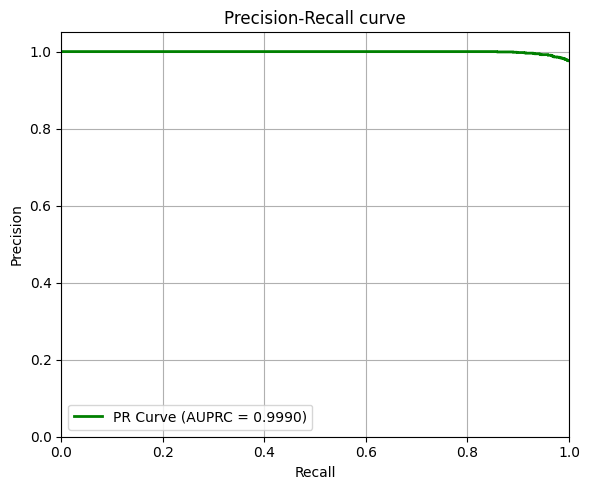

In [79]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score, 
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,  
    precision_recall_curve,
    precision_score,  
    recall_score,
    roc_auc_score,
    roc_curve,
)

y_true = np.array([0] * len(test_errors) + [1] * len(errors))
y_scores = np.concatenate([test_errors.numpy(), errors.numpy()])

# 2. Metrics
threshold = 0.15
y_pred = (y_scores > threshold).astype(int)

print(
    classification_report(
        y_true, y_pred, target_names=["Normal (0)", "Anomaly (1)"]
    )
)

# ========================================
# A. Confusion matrix
# ========================================
cm = confusion_matrix(y_true, y_pred)

TN, FP, FN, TP = cm.ravel()
accuracy = accuracy_score(y_true, y_pred)
precision_val = precision_score(y_true, y_pred) 
recall_val = recall_score(y_true, y_pred)  
f1 = f1_score(y_true, y_pred)
specificity = TN / (TN + FP) if (TN + FP) > 0 else 0

print("=== Some metrics (threshold = 0.15) ===")
print(f"Accuracy    : {accuracy:.4f}")
print(f"Precision   : {precision_val:.4f}")
print(f"Recall (TP) : {recall_val:.4f}")
print(f"Specificity : {specificity:.4f}")
print(f"F1-score    : {f1:.4f}")
print("-" * 45)

plt.figure(figsize=(6, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=["Normal", "Anomaly"]
)
disp.plot(cmap=plt.cm.Blues, values_format="d", ax=plt.gca())
plt.title("Confusion matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.pdf", dpi=300)
plt.show()

# ========================================
# B. Curve ROC & AUROC
# ========================================
fpr, tpr, _ = roc_curve(y_true, y_scores)
auroc = roc_auc_score(y_true, y_scores)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color="b", lw=2, label=f"ROC (AUROC = {auroc:.4f})")
plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False positive rate (FPR)") 
plt.ylabel("True positive rate (TPR)")
plt.title("ROC (Receiver Operating Characteristic) curve")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.savefig("roc_curve.pdf", dpi=300)
plt.show()

# ========================================
# C. Curve Precision-Recall & AUPRC
# ========================================
prec_curve, rec_curve, _ = precision_recall_curve(y_true, y_scores)
auprc = average_precision_score(y_true, y_scores)

plt.figure(figsize=(6, 5))
plt.plot(
    rec_curve,
    prec_curve,
    color="g",
    lw=2,
    label=f"PR Curve (AUPRC = {auprc:.4f})",
)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall curve")
plt.legend(loc="lower left")
plt.grid(True)
plt.tight_layout()
plt.savefig("pr_curve.pdf", dpi=300)
plt.show()